# Intermolecular interactions: day 2



In [1]:
import pandas as pd
from scipy.constants import (
    Boltzmann as k_B,
    Avogadro as N_A,
    epsilon_0,
    elementary_charge as e,
)
import numpy as np
import matplotlib.pyplot as plt


## Electrostatic energy in different solvents

We calculate the electrostatic energy between two charges (+-) in different dielectric media and at different temperatures. We shall do the calculation on both reduced units, and using SI. Note that when there's a temperature dependent dielectric constant, $\epsilon_r(T)$, it's no longer an energy, but a free energy. See more below.
$$
u(r) = \frac{q_1q_2}{4\pi\epsilon_0\epsilon_rr}
$$
where $q_i = z_i e$. In units of the thermal energy, $k_BT$ we write:

$$
\frac{u(r)}{k_BT} = \frac{\ell_B z_1z_2}{r}
$$
where $\ell_B = e^2 / 4\pi\epsilon_0\epsilon_rk_BT$ is the Bjerrum length. If we want energy per mole, we can instead divide by the molar thermal energy, $RT = k_BTN_A$.

In [2]:
from scipy.constants import (
    Boltzmann as k_B,
    Avogadro as N_A,
    epsilon_0,
    elementary_charge as e,
)

def bjerrum_length(T, epsilon_r):
    """Bjerrum length (Å)"""
    return e**2 / (4 * np.pi * epsilon_r * epsilon_0 * k_B * T) * 1e10

def energy(z1z2, epsilon_r, r):
    """energy in J given charge number product and r in angstrom"""
    c = e**2 / (4 * np.pi * epsilon_0 * epsilon_r)
    return c * z1z2 / (r * 1e-10)

def energy_reduced(z1z2, lB, r):
    """energy in reduced units, i.e. in units of kT"""
    return lB * z1z2 / r

r = 10     # Ion-ion separation, Å
z1z2 = -1  # charge product in units of e
solvents = [
    ("vacuum", 1.0, 300),
    ("water", 80, 300),
    ("water", 56, 370),
    ("EtOH", 24, 300),
    ("MeOH", 33, 300),
]

for name, epsilon_r, T in solvents:
    kT = k_B * T  # the thermal energy in J
    u = energy(z1z2, epsilon_r, r)
    print(f"{name:7} {T} K   u = {u * N_A / 1000:6.1f} kJ/mol = {u / kT:.2f} kT")

print("\nNow let's use the reduced unit function:\n")
for name, epsilon_r, T in solvents:
    kT = k_B * T  # the thermal energy in J
    lB = bjerrum_length(T, epsilon_r)
    u = energy_reduced(z1z2, lB, r)
    print(f"{name:7} {T} K  lB = {lB:6.2f} Å  u = {u:6.2f} kT = {u * kT * N_A / 1000:.1f} kJ/mol")

vacuum  300 K   u = -138.9 kJ/mol = -55.70 kT
water   300 K   u =   -1.7 kJ/mol = -0.70 kT
water   370 K   u =   -2.5 kJ/mol = -0.81 kT
EtOH    300 K   u =   -5.8 kJ/mol = -2.32 kT
MeOH    300 K   u =   -4.2 kJ/mol = -1.69 kT

Now let's use the reduced unit function:

vacuum  300 K  lB = 557.00 Å  u = -55.70 kT = -138.9 kJ/mol
water   300 K  lB =   6.96 Å  u =  -0.70 kT = -1.7 kJ/mol
water   370 K  lB =   8.06 Å  u =  -0.81 kT = -2.5 kJ/mol
EtOH    300 K  lB =  23.21 Å  u =  -2.32 kT = -5.8 kJ/mol
MeOH    300 K  lB =  16.88 Å  u =  -1.69 kT = -4.2 kJ/mol


## Electric potential around an ion

We can work in SI units, i.e. J/C = volt (V), or we can use the Bjerrum length and reduced units. Below shows how to convert between them.

In [3]:
def potential(z, epsilon_r, r):
    """electric potential at r (Å) in volts, V = J / C"""
    c = e / (4 * np.pi * epsilon_0 * epsilon_r)
    return c * z / (r * 1e-10)


def potential_reduced(z, lB, r):
    """electric potential at r (Å) in reduced units kT/e"""
    return lB * z / r


T = 300         # Temperature, K
kT = k_B * T    # Thermal energy in J
r = 20          # Distance from ion, Å
epsilon_r = 80  # relative dielectric constant
z = 2           # Charge number of ion in units of e

lB = bjerrum_length(T, epsilon_r)

print(f"Electric potential = {potential(z, epsilon_r, r) * 1000:.2f} mV")
print(f"Reduced electric potential = {potential_reduced(z, lB, r):.2f} kT/e")
print(
    f"Converted electric potential = {potential_reduced(z, lB, r) * kT / e * 1000:.2f} mV"
)

Electric potential = 18.00 mV
Reduced electric potential = 0.70 kT/e
Converted electric potential = 18.00 mV


## Charge perpendicular to a dipole

A point on the perpendicular bisector of a dipole is equally far, $r$, from $+q$ and $-q$, so by superposition

$$
\phi = \frac{1}{4\pi\epsilon_0\epsilon_r}\left(\frac{q}{r} - \frac{q}{r}\right) = 0.
$$

The potential is zero everywhere on that plane: moving a test charge in from infinity along it costs no work. The *field* is not zero there; it points along the dipole axis, from $+q$ towards $-q$.

## Entropy and energy of ion-ion interactions in a medium

The Coulomb potential in a medium is a free energy, $A = U - TS = \frac{q_1q_2}{4\pi\epsilon_0\epsilon_r(T) r}$ since the relative dielectric constant is temperature dependent. Using thermodynamics,
$$
S = -\partial A / \partial T =  \frac{q_1q_2}{4\pi\epsilon_0\epsilon_r^2(T) r} \left ( \frac{\partial  \epsilon_r}{\partial T} \right ) = \frac{A}{\epsilon_r(T)} \left ( \frac{\partial  \epsilon_r}{\partial T} \right )
$$

<details>
<summary>🤓 Click for expanded math.</summary>
To differentiate, use the chain rule and replace $f(x)$ with $\epsilon_r(T)$:
$$
\frac{d}{dx} \frac{1}{f(x)}
= \frac{d}{dx} f(x)^{-1}
= -1 \cdot f(x)^{-2} \cdot f^{\prime}(x)
= -\frac{f^{\prime}(x)}{f(x)^2}
$$
</details>

,0,1,2,3,4,5,6,7
ε_r,37.916,35.678,32.621,29.839,88.0,83.4,78.4,75.0
T,0,10,25,40,0,10,25,35
Compound,MeOH,MeOH,MeOH,MeOH,HOH,HOH,HOH,HOH


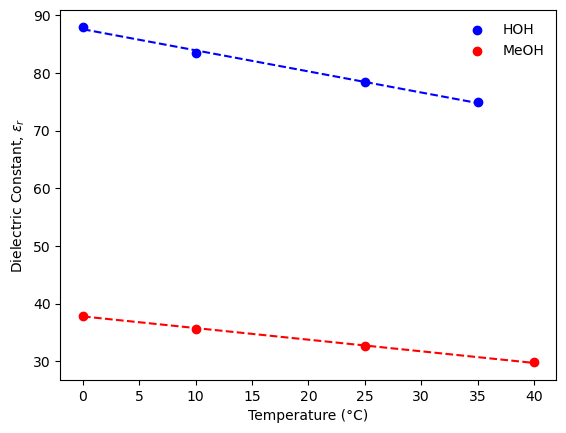

In [47]:
# Experimental data
def make_df():
    '''Make a simple database of experimental data for epsilon_r(T)'''
    meoh_data = pd.DataFrame({
        "ε_r": [37.916, 35.678, 32.621, 29.839],
        "T": [0, 10, 25, 40],
    })
    meoh_data["Compound"] = "MeOH"
    
    hoh_data = pd.DataFrame({
        "ε_r": [88, 83.4, 78.4, 75],
        "T": [0, 10, 25, 35],
    })
    hoh_data["Compound"] = "HOH"
    return pd.concat([meoh_data, hoh_data], ignore_index=True)



def plot_and_fit():
    """Plot and return fitted slopes dε_r / dT in units of 1/K"""
    slopes = {}
    colors = {"MeOH": "red", "HOH": "blue"}
    for compound, group in df.groupby("Compound"):
        T = group["T"].values
        eps = group["ε_r"].values
        slope, intersect = np.polyfit(T, eps, 1)
        slopes[compound] = slope

        T_fit = np.linspace(T.min(), T.max(), 50)
        eps_fit = slope * T_fit + intersect
        plt.scatter(T, eps, label=f"{compound}", c=colors[compound])
        plt.plot(T_fit, eps_fit, linestyle="--", c=colors[compound])

    plt.xlabel(r"Temperature (°C)")
    plt.ylabel(r"Dielectric Constant, $\epsilon_r$")
    plt.legend(frameon=False)
    return slopes

df = make_df()
slopes = plot_and_fit()
df.T

In [5]:
slopes

{'HOH': np.float64(-0.36551724137931024),
 'MeOH': np.float64(-0.20152108843537378)}

In [51]:
# The energy change in water of changing charge separation from 100 -> 10 Å:
d1 = 100e-10   # Distance, m
d2 = 10e-10    # Distance, m
T  = 300       # Temperature, K
kT = k_B * T   # Thermal energy, J

epsilon_r = 80
A = -e**2 / (4 * np.pi * epsilon_0 * epsilon_r) * (1/d2 - 1/d1)
S = A / epsilon_r * slopes["HOH"]
U = A + T*S
print(f"Water:    βΔA = {A / kT:5.2f}  βΔU = {U / kT:5.2f}  ΔS = {S:5.2e} = {S/k_B:.2f} k_B")

epsilon_r = 33
A = -e**2 / (4 * np.pi * epsilon_0 * epsilon_r) * (1/d2 - 1/d1)
S = A / epsilon_r * slopes["MeOH"]
U = A + T*S
print(f"Methanol: βΔA = {A / kT:5.2f}  βΔU = {U / kT:5.2f}  ΔS = {S:5.2e} = {S/k_B:.2f} k_B")

Water:    βΔA = -0.63  βΔU =  0.23  ΔS = 1.19e-23 = 0.86 k_B
Methanol: βΔA = -1.52  βΔU =  1.26  ΔS = 3.84e-23 = 2.78 k_B


## Charges on a grid

Consider three charges in the 2D grid below. For $q_1=q_2=0.5e$ and $q_3=-1e$, calculate the following:

1. total electrostatic energy in J and in kJ/mol
2. potential at q2 due to the two other charges
4. dipole moment vector and magnitude in units of Debye.
3. Bonus: total force on q3 (vector)

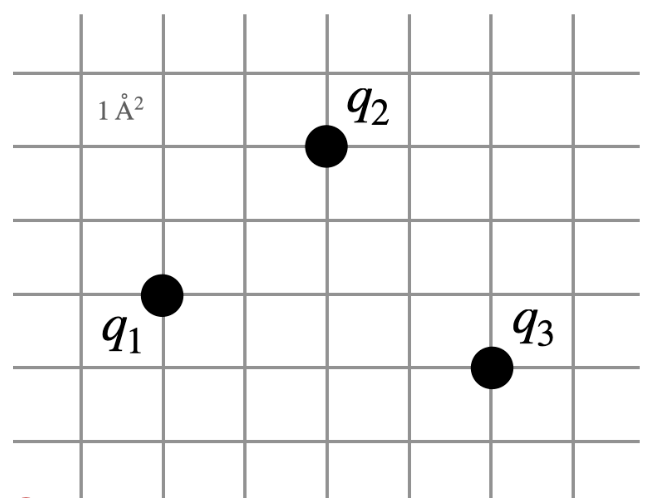

In [13]:
T = 298  # Temperature in K
eps_r = 80  # Relative dielectric constant
kT = k_B * T  # Thermal energy in J
lB = e**2 / (4 * np.pi * epsilon_0 * eps_r * kT) * 1e10  # in Å

print(f"Bjerrum length at 298K: {lB:.2f} Å")

# Define the three charges and their positions
charges = np.array([0.5, 0.5, -1.0])  # units of e
positions = np.array([[0.0, 0.0], [2.0, 2.0], [4.0, -1.0]])  # in Å


def calc_total_energy():
    """Total electrostatic energy in units of kT"""
    energy_sum = 0.0
    N = len(charges)
    for i in range(N):
        for j in range(i + 1, N):
            r_ij = np.linalg.norm(positions[i] - positions[j])  # distance in Å
            z_i = charges[i]
            z_j = charges[j]
            pair_energy = z_i * z_j / r_ij
            energy_sum += lB * pair_energy
            print(
                f"Pair ({i + 1},{j + 1}): r = {r_ij:.2f} Å, energy = {pair_energy:.3f} kT"
            )
    return energy_sum


total_energy = calc_total_energy()

print("\nTotal electrostatic energy:")
print(f"  In kT:          {total_energy:.2f} kT")
print(f"  In Joules:      {total_energy * kT:.2e} J")
print(f"  In kJ/mol:      {total_energy * kT * N_A / 1000:.2f} kJ/mol")

Bjerrum length at 298K: 7.01 Å
Pair (1,2): r = 2.83 Å, energy = 0.088 kT
Pair (1,3): r = 4.12 Å, energy = -0.121 kT
Pair (2,3): r = 3.61 Å, energy = -0.139 kT

Total electrostatic energy:
  In kT:          -1.20 kT
  In Joules:      -4.95e-21 J
  In kJ/mol:      -2.98 kJ/mol


In [14]:
def calc_potential_at_q2():
    """Returns the reduced potential at q2 - multiply by kT/e to get voltage"""
    z1 = charges[0]
    z3 = charges[2]
    r12 = np.linalg.norm(positions[1] - positions[0])
    r32 = np.linalg.norm(positions[1] - positions[2])
    return lB * (z1 / r12 + z3 / r32)  # reduced potential - unitless


phi = calc_potential_at_q2()
print(f"Reduced potential = {phi:.2f} kT/e")
print(f"Potential         = {phi * kT / e * 1000:.1f} mV")

Reduced potential = -0.70 kT/e
Potential         = -18.1 mV


In [15]:
def calc_dipole_moment(charges, positions):
    """
    Computes the dipole moment vector and magnitude in e·Å
    """
    mu = np.zeros(2)
    for i in range(len(charges)):
        mu += charges[i] * positions[i]  # units: e·Å
    return mu


mu = calc_dipole_moment(charges, positions)
print("Dipole moment:")
print(f"    vector = {mu} e·Å")
print(f"    magnitude = {np.linalg.norm(mu):.2f} e·Å")
print(f"    magnitude = {np.linalg.norm(mu) * e * 1e-10:.2e} C·m")
print(f"    magnitude = {np.linalg.norm(mu) * 4.80320427:.2f} Debye")

Dipole moment:
    vector = [-3.  2.] e·Å
    magnitude = 3.61 e·Å
    magnitude = 5.78e-29 C·m
    magnitude = 17.32 Debye


### Force on $q_3$

We define a reduced force in units of $k_BT$/Å:
$$
\mathbf{F}_3^{*} = -\nabla_{r3} U^{*} =  \sum_{i\neq 3} \frac{\ell_B z_3 z_i}{r_{3i}^2} \cdot \mathbf{\hat{r}}_{3i}
$$
Get SI units with $\mathbf{F} = \mathbf{F}^{*} \cdot k_BT \cdot 10^{10}$ Å/M to get J/m = N. See also Dill & Bromberg, 2nd Ed, Eq. 20.10.

In [19]:
def calc_force_on_q3():
    """Compute the electric force vector on q3 (index 2)"""
    q3_index = 2
    force_vector = np.zeros(2)
    pos_q3 = positions[q3_index]
    z3 = charges[q3_index]

    for i in range(len(charges)):
        if i == q3_index:
            continue
        z_i = charges[i]
        r_vec = pos_q3 - positions[i]         # vector from q_i to q3
        r_mag = np.linalg.norm(r_vec)         # norm of vector = magnitude or "length"
        r_hat = r_vec / r_mag                 # unit vector
        f_mag = (z3 * z_i) / (r_mag**2)       # reduced force magnitude (unitless)
        force_vector += f_mag * r_hat         # sum contributions

    return lB * force_vector      # reduced force kT/Å

force_vector = calc_force_on_q3()
print(f"Force vector = {force_vector} kT/Å")
force_magnitude = np.linalg.norm(force_vector)
print(f"Force magnitude on q3 = {force_magnitude:.2f} kT/Å = {force_magnitude * kT * 1e10:.2e} J/m (= N)")

Force vector = [-0.34953975  0.27431005] kT/Å
Force magnitude on q3 = 0.44 kT/Å = 1.83e-11 J/m (= N)


### Visualize the force (extra)

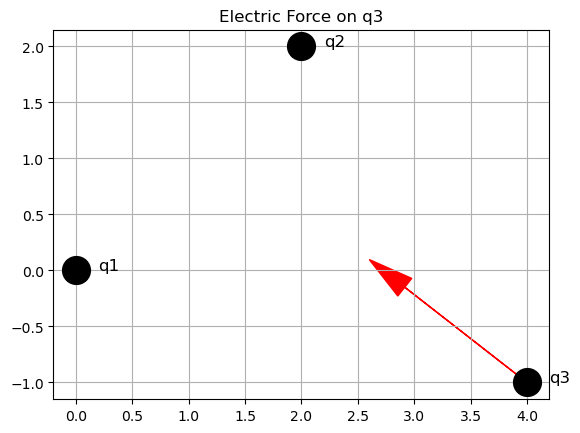

In [20]:
def plot_force_on_q3(positions, force_vector, scale=1.0):
    """
    Plot charges and force vector acting on q3.
    """
    # Plot charges as solid circles
    fig, ax = plt.subplots()
    labels = ['q1', 'q2', 'q3']

    for (pos, label) in zip(positions, labels):
        ax.plot(pos[0], pos[1], 'o', color='k', ms=20)
        ax.text(pos[0] + 0.2, pos[1] + 0.0, label, fontsize=12)

    # Illustrate force vector using an arrow
    q3_pos = positions[2]
    ax.arrow(
        q3_pos[0], q3_pos[1], 
        scale * force_vector[0], scale * force_vector[1], 
        head_width=0.2, head_length=0.4, fc='red', ec='red', 
        length_includes_head=True
    )
    ax.set_title('Electric Force on q3')
    ax.grid(True)
    plt.show()

plot_force_on_q3(positions, force_vector, scale=4)